# code_143 · Accepting synthetic datasets: fidelity, utility and disclosure

**Book:** section 27.6. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_143).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3343;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3343


<a id="acceptance-evidence-contract"></a>
 ## A generator needs an acceptance contract, not one quality number
 One hundred generated entities each supply eight records: source60/development20/final20 whole entities. A binary risk label selects correlated log load/stiffness summaries. A deliberately conspicuous [8,8] source-only canary is inserted at record0; it is an artificial audit fixture, not a private person. Compare a memorizing source bootstrap, independent field marginals and source-fit label-conditional Gaussian mixtures (components1/2 chosen by development log density). Each draws3,000 records for diagnostics; the first480 provide equal-size synthetic-only or augmentation classifier training. Common source-fitted scaling and fixed LogisticRegression C1 preserve the downstream control. A nearest-synthetic-row membership attack chooses its distance threshold using known source members1:240 and development nonmembers, then evaluates remaining source members against untouched final nonmembers. This scoped empirical attack does not establish or refute a differential-privacy parameter.


,generator,mean_marginal_Wasserstein,generated_correlation,reference_correlation,generated_rare_tail_fraction_logload_gt2,reference_rare_tail_fraction
0,Source bootstrap,0.098782,0.819044,0.835466,0.076000,0.09375
1,Independent marginals,0.113968,-0.050528,0.835466,0.077667,0.09375
2,Conditional mixture,0.116134,0.844255,0.835466,0.072333,0.09375


,training,records,training_risk_fraction,final_Brier,final_average_precision
0,Source only,480,0.160417,0.096472,0.664572
1,Source bootstrap synthetic only,480,0.166667,0.095017,0.663803
2,Source bootstrap augmented,960,0.163542,0.095788,0.668063
3,Independent marginals synthetic only,480,0.177083,0.146856,0.102062
4,Independent marginals augmented,960,0.168750,0.108444,0.660986
5,Conditional mixture synthetic only,480,0.141667,0.096739,0.668063
6,Conditional mixture augmented,960,0.151042,0.096871,0.665798


,generator,calibrated_distance_threshold,held_out_membership_AUC,held_out_membership_balanced_accuracy,generated_exact_source_copy_fraction,canary_exact_copies,canary_nearest_distance,attack_test_members,attack_test_nonmembers
0,Source bootstrap,0.000000,0.998359,0.997917,1.000000,2,0.000000,240,160
1,Independent marginals,0.018275,0.537995,0.525000,0.001667,0,8.163523,240,160
2,Conditional mixture,0.038962,0.484714,0.501042,0.000000,0,0.001004,240,160


Separate constraints: {'orphan_parents': 0, 'orphan_inspections': 0, 'report_before_event': 0, 'response_ratio_violations': 0} {'orphan_parents': 0, 'orphan_inspections': 15, 'report_before_event': 47, 'response_ratio_violations': 3000}


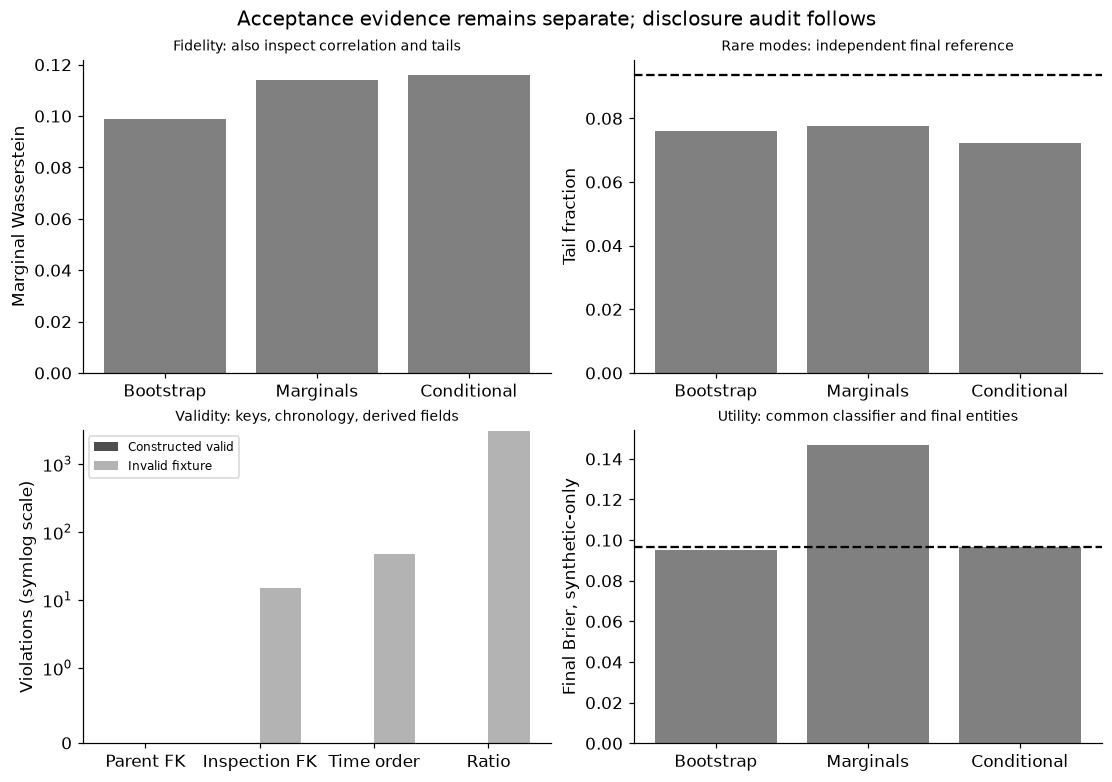

In [2]:
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import brier_score_loss,average_precision_score,roc_auc_score,balanced_accuracy_score
from scipy.stats import wasserstein_distance
B,R=100,8;entity=np.repeat(np.arange(B),R);label=rng.binomial(1,.15,B*R);mode=rng.binomial(1,.25+.25*label);raw=np.column_stack([.7*label+1.4*mode, .4*label+.8*mode])+rng.multivariate_normal([0,0],[[.2,.13],[.13,.2]],B*R)+rng.normal(0,.1,(B,2))[entity];raw[0]=[8.,8.];label[0]=1;source=entity<60;dev=(entity>=60)&(entity<80);final=entity>=80;center=raw[source].mean(0);spread=raw[source].std(0);z=(raw-center)/spread;prior=float(label[source].mean());mixtures={};selection=[]
for c in [0,1]:
    choices=[]
    for components in [1,2]:
        model=GaussianMixture(components,reg_covar=1e-5,n_init=2,random_state=SEED,max_iter=300).fit(z[source&(label==c)]);assert model.converged_;score=float(model.score(z[dev&(label==c)]));selection.append({'condition':c,'components':components,'development_log_density':score});choices.append((score,model))
    mixtures[c]=max(choices,key=lambda pair:pair[0])[1]
def draw_mix(model,n):
    choices=rng.choice(model.n_components,n,p=model.weights_);out=np.empty((n,2))
    for j in range(model.n_components):ids=np.flatnonzero(choices==j);out[ids]=rng.multivariate_normal(model.means_[j],model.covariances_[j],len(ids))
    return out
generators={};N=3000
for name in ['Source bootstrap','Independent marginals','Conditional mixture']:
    if name=='Source bootstrap':ids=rng.choice(np.flatnonzero(source),N);sample=z[ids];c=label[ids]
    elif name=='Independent marginals':sample=np.column_stack([rng.choice(z[source,j],N) for j in range(2)]);c=rng.binomial(1,prior,N)
    else:
        c=rng.binomial(1,prior,N);sample=np.empty((N,2))
        for value in [0,1]:ids=np.flatnonzero(c==value);sample[ids]=draw_mix(mixtures[value],len(ids))
    generators[name]=(sample,c)
def classifier_metrics(name,x,y):
    classifier=LogisticRegression(C=1,max_iter=500).fit(x,y);p=classifier.predict_proba(z[final])[:,1];return {'training':name,'records':len(y),'training_risk_fraction':float(y.mean()),'final_Brier':float(brier_score_loss(label[final],p)),'final_average_precision':float(average_precision_score(label[final],p))}
utility=[classifier_metrics('Source only',z[source],label[source])];fidelity=[];disclosure=[];cal_members=np.arange(1,240);test_members=np.arange(240,480);nonmembers_dev=np.flatnonzero(dev);nonmembers_final=np.flatnonzero(final);canary=z[[0]]
for name,(sample,c) in generators.items():
    utility.append(classifier_metrics(name+' synthetic only',sample[:480],c[:480]));utility.append(classifier_metrics(name+' augmented',np.vstack([z[source],sample[:480]]),np.r_[label[source],c[:480]]));natural=sample*spread+center;reference=raw[final];fidelity.append({'generator':name,'mean_marginal_Wasserstein':float(np.mean([wasserstein_distance(sample[:,j],z[final,j]) for j in range(2)])),'generated_correlation':float(np.corrcoef(sample.T)[0,1]),'reference_correlation':float(np.corrcoef(z[final].T)[0,1]),'generated_rare_tail_fraction_logload_gt2':float(np.mean(natural[:,0]>2)),'reference_rare_tail_fraction':float(np.mean(reference[:,0]>2))})
    nearest=NearestNeighbors(n_neighbors=1,algorithm='kd_tree').fit(sample)
    def proximity(indices):return nearest.kneighbors(z[indices],return_distance=True)[0][:,0]
    member_cal=proximity(cal_members);non_cal=proximity(nonmembers_dev);dist=np.r_[member_cal,non_cal];truth=np.r_[np.ones(len(member_cal)),np.zeros(len(non_cal))];thresholds=np.r_[0.,np.quantile(dist,np.linspace(0,1,101))];scores=[balanced_accuracy_score(truth,dist<=threshold) for threshold in thresholds];threshold=float(thresholds[int(np.argmax(scores))]);member=proximity(test_members);nonmember=proximity(nonmembers_final);truth_test=np.r_[np.ones(len(member)),np.zeros(len(nonmember))];distance_test=np.r_[member,nonmember];canary_distance=float(np.min(np.linalg.norm(sample-canary,axis=1)));copies=int(np.sum(np.linalg.norm(sample-canary,axis=1)<1e-12));source_nearest=NearestNeighbors(n_neighbors=1,algorithm='kd_tree').fit(z[source]).kneighbors(sample,return_distance=True)[0][:,0]
    disclosure.append({'generator':name,'calibrated_distance_threshold':threshold,'held_out_membership_AUC':float(roc_auc_score(truth_test,-distance_test)),'held_out_membership_balanced_accuracy':float(balanced_accuracy_score(truth_test,distance_test<=threshold)),'generated_exact_source_copy_fraction':float(np.mean(source_nearest<1e-12)),'canary_exact_copies':copies,'canary_nearest_distance':canary_distance,'attack_test_members':len(member),'attack_test_nonmembers':len(nonmember)})
# Derived-field constraints and linked keys are checked independently of density.
sample,c=generators['Conditional mixture'];load=np.exp(sample[:,0]*spread[0]+center[0]);stiffness=np.exp(sample[:,1]*spread[1]+center[1]);response=load/stiffness;bad_response=rng.permutation(response);valid_ratio=int(np.sum(~np.isclose(response,load/stiffness,rtol=1e-10,atol=1e-12)));invalid_ratio=int(np.sum(~np.isclose(bad_response,load/stiffness,rtol=1e-10,atol=1e-12)))
parent=np.repeat(np.arange(30),3);member_id=np.arange(len(parent));inspection_member=member_id.copy();event=rng.uniform(0,20,len(parent));report=event+rng.exponential(1,len(parent));bad_foreign=rng.integers(0,len(parent)+20,len(parent));bad_report=event+rng.normal(0,1,len(parent));valid={'orphan_parents':int(np.sum(~np.isin(parent,np.arange(30)))),'orphan_inspections':int(np.sum(~np.isin(inspection_member,member_id))),'report_before_event':int(np.sum(report<event)),'response_ratio_violations':valid_ratio};invalid={'orphan_parents':0,'orphan_inspections':int(np.sum(~np.isin(bad_foreign,member_id))),'report_before_event':int(np.sum(bad_report<event)),'response_ratio_violations':invalid_ratio}
assert sum(valid.values())==0 and sum(invalid.values())>0
bootstrap=next(row for row in disclosure if row['generator']=='Source bootstrap');assert bootstrap['generated_exact_source_copy_fraction']==1 and bootstrap['canary_exact_copies']>0
RESULTS.update(building_counts=[60,20,20],record_counts=[int(source.sum()),int(dev.sum()),int(final.sum())],source_label_prevalence=prior,generated_records_per_recipe=N,synthetic_classifier_records=480,mixture_selection=selection,selected_components={str(c):m.n_components for c,m in mixtures.items()},fidelity=fidelity,utility=utility,disclosure=disclosure,valid_constraints=valid,deliberately_invalid_constraints=invalid,canary_original_log_coordinates=[8.,8.]);display(pd.DataFrame(fidelity));display(pd.DataFrame(utility));display(pd.DataFrame(disclosure));print('Separate constraints:',valid,invalid)
fig,axes=plt.subplots(2,2,figsize=(10,7));names=['Bootstrap','Marginals','Conditional'];xx=np.arange(3);axes[0,0].bar(xx,[r['mean_marginal_Wasserstein'] for r in fidelity],color='.5');axes[0,0].set(xticks=xx,xticklabels=names,ylabel='Marginal Wasserstein',title='Fidelity: also inspect correlation and tails');axes[0,1].bar(xx,[r['generated_rare_tail_fraction_logload_gt2'] for r in fidelity],color='.5');axes[0,1].axhline(fidelity[0]['reference_rare_tail_fraction'],color='black',linestyle='--');axes[0,1].set(xticks=xx,xticklabels=names,ylabel='Tail fraction',title='Rare modes: independent final reference');axes[1,0].bar(np.arange(4)-.18,list(valid.values()),.36,label='Constructed valid',color='.3');axes[1,0].bar(np.arange(4)+.18,list(invalid.values()),.36,label='Invalid fixture',color='.7');axes[1,0].set(xticks=np.arange(4),xticklabels=['Parent FK','Inspection FK','Time order','Ratio'],ylabel='Constraint violations',title='Validity: keys, chronology, derived fields');axes[1,0].legend(fontsize=8);axes[1,0].set_yscale('symlog',linthresh=1);axes[1,0].set_ylabel('Violations (symlog scale)');synthetic_rows=utility[1::2];axes[1,1].bar(xx,[r['final_Brier'] for r in synthetic_rows],color='.5');axes[1,1].axhline(utility[0]['final_Brier'],color='black',linestyle='--');axes[1,1].set(xticks=xx,xticklabels=names,ylabel='Final Brier, synthetic-only',title='Utility: common classifier and final entities');fig.suptitle('Acceptance evidence remains separate; disclosure audit follows');plt.show()


<a id="privacy-and-acceptance-limits"></a>
 ## Novel rows and failed attacks are incomplete privacy evidence
 Membership diagnostics compare held-out known source rows with independent final rows, after attack-threshold calibration on a different known-member subset and development nonmembers. This attack assumes access to both generated records and some known memberships; it is not an adversary-free guarantee. Exact-copy tolerance is explicit, and the conspicuous canary is only a diagnostic fixture. The fitted mixture may emit no identical rows while preserving source-specific information, and a failed proximity attack leaves other attacks untested. The bootstrap intentionally memorizes. All data here, including the source canary, are generated without private records. No DP training, privacy accountant or formal epsilon/delta is implemented. If a task requires formal privacy, changing the generator label or postprocessing these outputs supplies no such guarantee. Physical ratios, foreign keys and chronology are audited separately from distributional fidelity and downstream classifier scores.


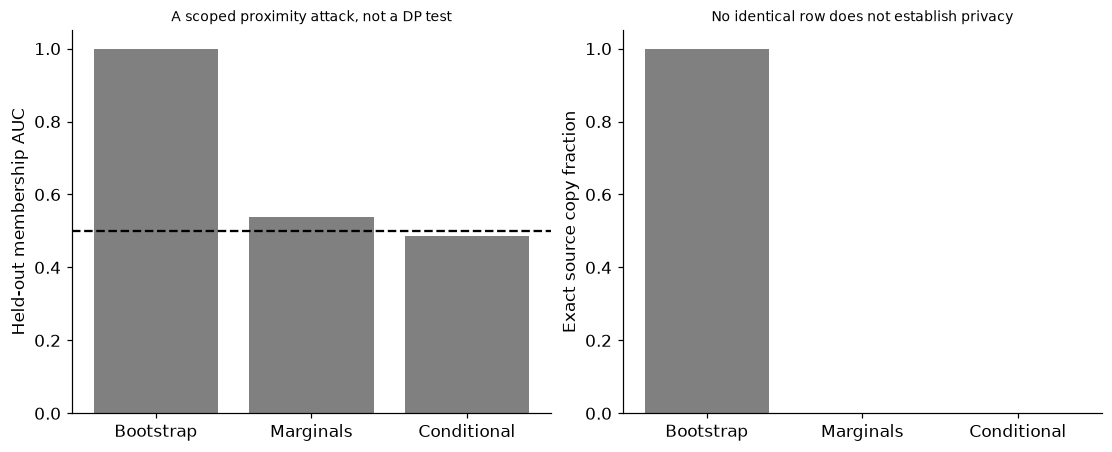

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(3);axes[0].bar(xx,[r['held_out_membership_AUC'] for r in disclosure],color='.5');axes[0].axhline(.5,color='black',linestyle='--');axes[0].set(xticks=xx,xticklabels=['Bootstrap','Marginals','Conditional'],ylim=(0,1.05),ylabel='Held-out membership AUC',title='A scoped proximity attack, not a DP test');axes[1].bar(xx,[r['generated_exact_source_copy_fraction'] for r in disclosure],color='.5');axes[1].set(xticks=xx,xticklabels=['Bootstrap','Marginals','Conditional'],ylim=(0,1.05),ylabel='Exact source copy fraction',title='No identical row does not establish privacy');plt.show()
assert all(np.isfinite(r['final_Brier']) for r in utility)


In [4]:
summary={'example_id':'code_143','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['separate fidelity utility schema and disclosure evidence', 'actual source-only synthetic-only and augmented classifiers', 'development-calibrated proximity membership attack on generated data', 'deliberate source canary and exact-copy audits', 'relational and derived-field acceptance checks without DP claims'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["separate fidelity utility schema and disclosure evidence", "actual source-only synthetic-only and augmented classifiers", "development-calibrated proximity membership attack on generated data", "deliberate source canary and exact-copy audits", "relational and derived-field acceptance checks without DP claims"], "elapsed_seconds": 1.42, "example_id": "code_143", "hardware": "Darwin arm64 CPU", "results": {"building_counts": [60, 20, 20], "canary_original_log_coordinates": [8.0, 8.0], "deliberately_invalid_constraints": {"orphan_inspections": 15, "orphan_parents": 0, "report_before_event": 47, "response_ratio_violations": 3000}, "disclosure": [{"attack_test_members": 240, "attack_test_nonmembers": 160, "calibrated_distance_threshold": 0.0, "canary_exact_copies": 2, "canary_nearest_distance": 0.0, "generated_exact_source_copy_fraction": 1.0, "generator": "Source bootstrap", "held_out_membership_AUC": 0.9983593749999999, "held_out_membersh